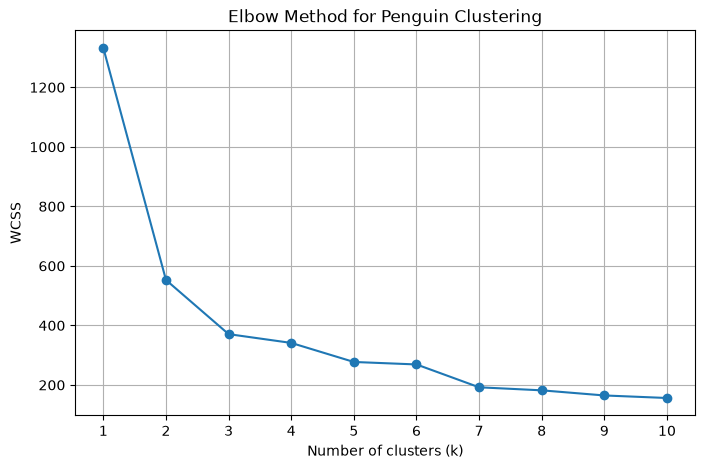

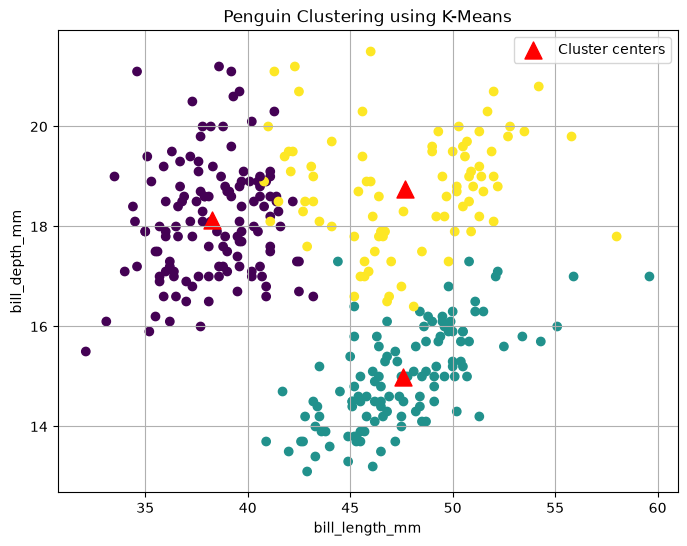

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("penguins.csv")
df = df.dropna().copy()

k = int(input("Enter number of clusters: "))

# Select all numerical features used for clustering
features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

# Scale the features
scaler = StandardScaler()
X = scaler.fit_transform(df[features].values)

np.random.seed(23)

# Initialize clusters for any number of features
clusters = {}

for idx in range(k):
    center = X[np.random.randint(0, len(X))].copy()

    clusters[idx] = {
        "center": center,
        "points": []
    }


def distance(p1, p2):
    return np.sqrt(np.sum((p1 - p2) ** 2))

wcss = []

for k_test in range(1, 11):
    temp_clusters = {}

    # Initialize centers from random data points
    np.random.seed(23)
    indices = np.random.choice(
        len(X), size=k_test, replace=False
    )

    for idx in range(k_test):
        temp_clusters[idx] = {
            "center": X[indices[idx]].copy(),
            "points": []
        }

    # Run K-Means for this value of k
    for iteration in range(100):
        old_centers = np.array([
            temp_clusters[i]["center"].copy()
            for i in range(k_test)
        ])

        # Clear old assignments
        for cluster in temp_clusters.values():
            cluster["points"] = []

        # Assign points to nearest center
        for point in X:
            distances = [
                distance(point, temp_clusters[j]["center"])
                for j in range(k_test)
            ]

            closest = np.argmin(distances)
            temp_clusters[closest]["points"].append(point)

        # Update centers
        for i in range(k_test):
            points = np.array(temp_clusters[i]["points"])

            if len(points) > 0:
                temp_clusters[i]["center"] = points.mean(axis=0)

        new_centers = np.array([
            temp_clusters[i]["center"]
            for i in range(k_test)
        ])

        if np.allclose(old_centers, new_centers):
            break

    total_wcss = 0

    for i in range(k_test):
        points = np.array(temp_clusters[i]["points"])
        center = temp_clusters[i]["center"]

        if len(points) > 0:
            total_wcss += np.sum((points - center) ** 2)

    wcss.append(total_wcss)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("WCSS")
plt.title("Elbow Method for Penguin Clustering")
plt.xticks(range(1, 11))
plt.grid()
plt.show()


def assign_clusters(X, clusters):
    for cluster in clusters.values():
        cluster["points"] = []

    for point in X:
        distances = [
            distance(point, clusters[i]["center"])
            for i in range(k)
        ]

        closest = np.argmin(distances)
        clusters[closest]["points"].append(point)

    return clusters


def update_clusters(clusters):
    for i in range(k):
        points = np.array(clusters[i]["points"])

        if len(points) > 0:
            clusters[i]["center"] = points.mean(axis=0)

    return clusters


def pred_cluster(X, clusters):
    predictions = []

    for point in X:
        distances = [
            distance(point, clusters[j]["center"])
            for j in range(k)
        ]

        predictions.append(np.argmin(distances))

    return predictions


# Run K-Means
max_iterations = 100

for iteration in range(max_iterations):
    old_centers = np.array([
        clusters[i]["center"].copy()
        for i in range(k)
    ])

    clusters = assign_clusters(X, clusters)
    clusters = update_clusters(clusters)

    new_centers = np.array([
        clusters[i]["center"]
        for i in range(k)
    ])

    if np.allclose(old_centers, new_centers):
        break

# Predict cluster for each penguin
predictions = pred_cluster(X, clusters)
df["cluster"] = predictions

# Convert centers back to original units
centres_scaled = np.array([
    clusters[i]["center"]
    for i in range(k)
])

centres = scaler.inverse_transform(centres_scaled)
x_feature = "bill_length_mm"
y_feature = "bill_depth_mm"

plt.figure(figsize=(8, 6))

plt.scatter(
    df[x_feature],
    df[y_feature],
    c=df["cluster"],
    cmap="viridis"
)

plt.scatter(
    centres[:, features.index(x_feature)],
    centres[:, features.index(y_feature)],
    marker="^",
    color="red",
    s=150,
    label="Cluster centers"
)

plt.xlabel(x_feature)
plt.ylabel(y_feature)
plt.title("Penguin Clustering using K-Means")
plt.legend()
plt.grid()
plt.show()



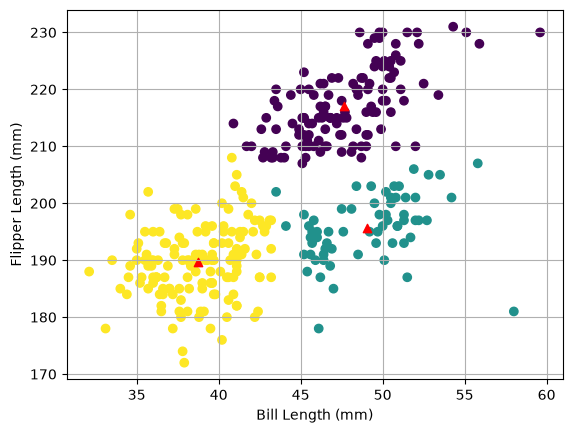

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df=pd.read_csv("/Users/yuktaranjalkar/Downloads/penguins.csv")
df=df.dropna()

k=int(input("enter number of clusters"))

clusters={}
np.random.seed(23)


features=["bill_length_mm","flipper_length_mm"]

data=df[features].values
mean=data.mean(axis=0)
std=data.std(axis=0)
X=(data-mean)/std

for idx in range(k):
    center=2*(2*np.random.random((X.shape[1],))-1)
    points=[]
    cluster={
        'center':center,
        'points':[]
    }
    clusters[idx]=cluster

def distance(p1, p2):
    return np.sqrt(np.sum((p1-p2)**2))

def assign_clusters(X, clusters):
    for idx in range(X.shape[0]):
        dist=[]
        currx=X[idx]
        for i in range(k):
            dis=distance(currx,clusters[i]['center'])
            dist.append(dis)
        currc=np.argmin(dist)
        clusters[currc]['points'].append(currx)
    return clusters

def update_clusters(X, clusters):
    for i in range(k):
        points=np.array(clusters[i]['points'])
        if points.shape[0]>0:
            new_center=points.mean(axis=0)
            clusters[i]['center']=new_center

            clusters[i]['points']=[]
    return clusters

def pred_cluster(X,clusters):
    pred=[]
    for i in range(X.shape[0]):
        dist=[]
        for j in range(k):
            dist.append(distance(X[i],clusters[j]['center']))
        pred.append(np.argmin(dist))
    return pred

max=100

for i in range(max):
    old_centers=[clusters[i]['center'].copy() for i in range(k)]

    clusters=assign_clusters(X, clusters)
    clusters=update_clusters(X, clusters)

    new_centers=[clusters[i]['center'] for i in range(k)]

    if np.allclose(old_centers, new_centers):
        break

pred=pred_cluster(X, clusters)
df["cluster"]=pred

centres_scaled=np.array([clusters[i]['center'] for i in range(k)])
centres=centres_scaled*std+mean

plt.grid()
plt.scatter(df[features[0]],df[features[1]],c=df["cluster"])
plt.scatter(centres[:, 0], centres[:, 1], marker='^',c='red')
plt.xlabel("Bill Length (mm)")
plt.ylabel("Flipper Length (mm)")
plt.show()

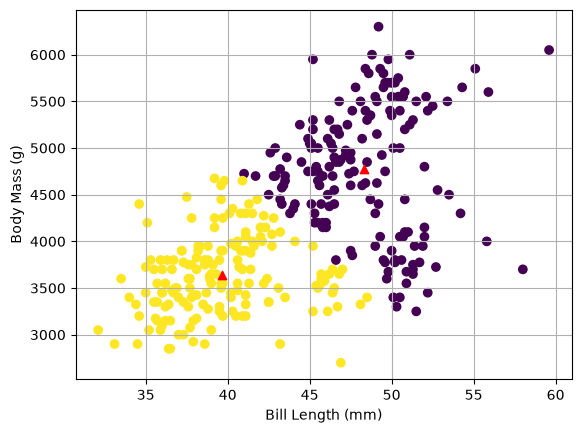

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df=pd.read_csv("/Users/yuktaranjalkar/Downloads/penguins.csv")
df=df.dropna()

k=int(input("enter number of clusters"))

clusters={}
np.random.seed(23)


features=["bill_length_mm","body_mass_g"]

data=df[features].values
mean=data.mean(axis=0)
std=data.std(axis=0)
X=(data-mean)/std

for idx in range(k):
    center=2*(2*np.random.random((X.shape[1],))-1)
    points=[]
    cluster={
        'center':center,
        'points':[]
    }
    clusters[idx]=cluster

def distance(p1, p2):
    return np.sqrt(np.sum((p1-p2)**2))

def assign_clusters(X, clusters):
    for idx in range(X.shape[0]):
        dist=[]
        currx=X[idx]
        for i in range(k):
            dis=distance(currx,clusters[i]['center'])
            dist.append(dis)
        currc=np.argmin(dist)
        clusters[currc]['points'].append(currx)
    return clusters

def update_clusters(X, clusters):
    for i in range(k):
        points=np.array(clusters[i]['points'])
        if points.shape[0]>0:
            new_center=points.mean(axis=0)
            clusters[i]['center']=new_center

            clusters[i]['points']=[]
    return clusters

def pred_cluster(X,clusters):
    pred=[]
    for i in range(X.shape[0]):
        dist=[]
        for j in range(k):
            dist.append(distance(X[i],clusters[j]['center']))
        pred.append(np.argmin(dist))
    return pred

max=100

for i in range(max):
    old_centers=[clusters[i]['center'].copy() for i in range(k)]

    clusters=assign_clusters(X, clusters)
    clusters=update_clusters(X, clusters)

    new_centers=[clusters[i]['center'] for i in range(k)]

    if np.allclose(old_centers, new_centers):
        break

pred=pred_cluster(X, clusters)
df["cluster"]=pred

centres_scaled=np.array([clusters[i]['center'] for i in range(k)])
centres=centres_scaled*std+mean

plt.grid()
plt.scatter(df[features[0]],df[features[1]],c=df["cluster"])
plt.scatter(centres[:, 0], centres[:, 1], marker='^',c='red')
plt.xlabel("Bill Length (mm)")
plt.ylabel("Body Mass (g)")
plt.show()

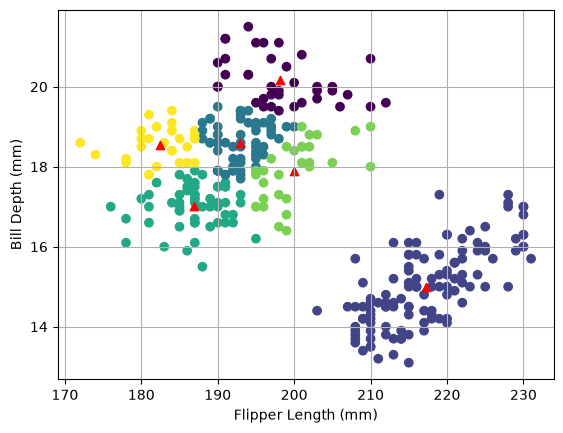

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df=pd.read_csv("/Users/yuktaranjalkar/Downloads/penguins.csv")
df=df.dropna()

k=int(input("enter number of clusters"))

clusters={}
np.random.seed(23)


features=["flipper_length_mm","bill_depth_mm"]

data=df[features].values
mean=data.mean(axis=0)
std=data.std(axis=0)
X=(data-mean)/std

for idx in range(k):
    center=2*(2*np.random.random((X.shape[1],))-1)
    points=[]
    cluster={
        'center':center,
        'points':[]
    }
    clusters[idx]=cluster

def distance(p1, p2):
    return np.sqrt(np.sum((p1-p2)**2))

def assign_clusters(X, clusters):
    for idx in range(X.shape[0]):
        dist=[]
        currx=X[idx]
        for i in range(k):
            dis=distance(currx,clusters[i]['center'])
            dist.append(dis)
        currc=np.argmin(dist)
        clusters[currc]['points'].append(currx)
    return clusters

def update_clusters(X, clusters):
    for i in range(k):
        points=np.array(clusters[i]['points'])
        if points.shape[0]>0:
            new_center=points.mean(axis=0)
            clusters[i]['center']=new_center

            clusters[i]['points']=[]
    return clusters

def pred_cluster(X,clusters):
    pred=[]
    for i in range(X.shape[0]):
        dist=[]
        for j in range(k):
            dist.append(distance(X[i],clusters[j]['center']))
        pred.append(np.argmin(dist))
    return pred

max=100

for i in range(max):
    old_centers=[clusters[i]['center'].copy() for i in range(k)]

    clusters=assign_clusters(X, clusters)
    clusters=update_clusters(X, clusters)

    new_centers=[clusters[i]['center'] for i in range(k)]

    if np.allclose(old_centers, new_centers):
        break

pred=pred_cluster(X, clusters)
df["cluster"]=pred

centres_scaled=np.array([clusters[i]['center'] for i in range(k)])
centres=centres_scaled*std+mean

plt.grid()
plt.scatter(df[features[0]],df[features[1]],c=df["cluster"])
plt.scatter(centres[:, 0], centres[:, 1], marker='^',c='red')
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Bill Depth (mm)")
plt.show()

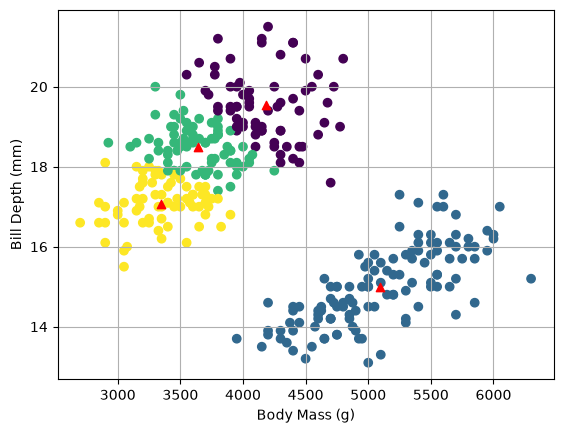

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df=pd.read_csv("/Users/yuktaranjalkar/Downloads/penguins.csv")
df=df.dropna()

k=int(input("enter number of clusters"))

clusters={}
np.random.seed(23)


features=["body_mass_g","bill_depth_mm"]

data=df[features].values
mean=data.mean(axis=0)
std=data.std(axis=0)
X=(data-mean)/std

for idx in range(k):
    center=2*(2*np.random.random((X.shape[1],))-1)
    points=[]
    cluster={
        'center':center,
        'points':[]
    }
    clusters[idx]=cluster

def distance(p1, p2):
    return np.sqrt(np.sum((p1-p2)**2))

def assign_clusters(X, clusters):
    for idx in range(X.shape[0]):
        dist=[]
        currx=X[idx]
        for i in range(k):
            dis=distance(currx,clusters[i]['center'])
            dist.append(dis)
        currc=np.argmin(dist)
        clusters[currc]['points'].append(currx)
    return clusters

def update_clusters(X, clusters):
    for i in range(k):
        points=np.array(clusters[i]['points'])
        if points.shape[0]>0:
            new_center=points.mean(axis=0)
            clusters[i]['center']=new_center

            clusters[i]['points']=[]
    return clusters

def pred_cluster(X,clusters):
    pred=[]
    for i in range(X.shape[0]):
        dist=[]
        for j in range(k):
            dist.append(distance(X[i],clusters[j]['center']))
        pred.append(np.argmin(dist))
    return pred

max=100

for i in range(max):
    old_centers=[clusters[i]['center'].copy() for i in range(k)]

    clusters=assign_clusters(X, clusters)
    clusters=update_clusters(X, clusters)

    new_centers=[clusters[i]['center'] for i in range(k)]

    if np.allclose(old_centers, new_centers):
        break

pred=pred_cluster(X, clusters)
df["cluster"]=pred

centres_scaled=np.array([clusters[i]['center'] for i in range(k)])
centres=centres_scaled*std+mean

plt.grid()
plt.scatter(df[features[0]],df[features[1]],c=df["cluster"])
plt.scatter(centres[:, 0], centres[:, 1], marker='^',c='red')
plt.xlabel("Body Mass (g)")
plt.ylabel("Bill Depth (mm)")
plt.show()

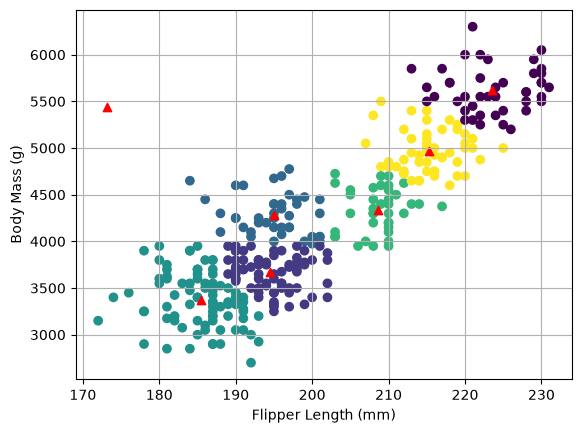

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df=pd.read_csv("/Users/yuktaranjalkar/Downloads/penguins.csv")
df=df.dropna()

k=int(input("enter number of clusters"))

clusters={}
np.random.seed(23)


features=["flipper_length_mm","body_mass_g"]

data=df[features].values
mean=data.mean(axis=0)
std=data.std(axis=0)
X=(data-mean)/std

for idx in range(k):
    center=2*(2*np.random.random((X.shape[1],))-1)
    points=[]
    cluster={
        'center':center,
        'points':[]
    }
    clusters[idx]=cluster

def distance(p1, p2):
    return np.sqrt(np.sum((p1-p2)**2))

def assign_clusters(X, clusters):
    for idx in range(X.shape[0]):
        dist=[]
        currx=X[idx]
        for i in range(k):
            dis=distance(currx,clusters[i]['center'])
            dist.append(dis)
        currc=np.argmin(dist)
        clusters[currc]['points'].append(currx)
    return clusters

def update_clusters(X, clusters):
    for i in range(k):
        points=np.array(clusters[i]['points'])
        if points.shape[0]>0:
            new_center=points.mean(axis=0)
            clusters[i]['center']=new_center

            clusters[i]['points']=[]
    return clusters

def pred_cluster(X,clusters):
    pred=[]
    for i in range(X.shape[0]):
        dist=[]
        for j in range(k):
            dist.append(distance(X[i],clusters[j]['center']))
        pred.append(np.argmin(dist))
    return pred

max=100

for i in range(max):
    old_centers=[clusters[i]['center'].copy() for i in range(k)]

    clusters=assign_clusters(X, clusters)
    clusters=update_clusters(X, clusters)

    new_centers=[clusters[i]['center'] for i in range(k)]

    if np.allclose(old_centers, new_centers):
        break

pred=pred_cluster(X, clusters)
df["cluster"]=pred

centres_scaled=np.array([clusters[i]['center'] for i in range(k)])
centres=centres_scaled*std+mean

plt.grid()
plt.scatter(df[features[0]],df[features[1]],c=df["cluster"])
plt.scatter(centres[:, 0], centres[:, 1], marker='^',c='red')
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (g)")
plt.show()